# Two-group representational dimensionality (PR)

Group-level analysis of FLT2's per-subject participation ratio (PR) for tonecat trials: learners (non-Mandarin) vs. native listeners (Mandarin). `09_integration/TWO_GROUP_MANUSCRIPT_PLAN.md` R5.

**Measure: cross-validated PR (`PRcv`).** Plain PR on stimulus-mean patterns is inflated by noise (pure noise gives near-maximal PR) and depends on trial and voxel counts, so a stage or group difference in it can just be a difference in signal-to-noise. `PRcv` takes the principal-component variances from the covariance between two independent halves of the trials, so noise drops out. The halves split each run's repetitions of a stimulus (FLT2 `trial_splits.py`), not runs: learners change from run to run, and a run split would count that learning as noise. Weak signal biases `PRcv` *low*, so every PRcv result is checked against the cross-validated signal variance (`cvsignal`, section 6).

The per-subject pipeline stays in FLT2 (GLMsingle → `mask_glmsingle_betas.py` → `dimensionality_roi.py`, fMRIPrep 25.2.5, T1w). This notebook only reads its `stage-*/sub-*_dimensionality_*.csv` outputs. `multivariate_data.py` turns them into the same long table `extract_roi_values.py` writes, so the two-group functions in `06_univariate/group_stats.py` run unchanged; the measure sits in the `beta` column with its name in `contrast`.

**Key question:** is the early → final PR decline learner-specific (learning-related compression) or shared (repetition/adaptation)?

**Before trusting anything here** (plan R5): FLT2's `dimensionality_roi.py` rerun (6bcaa4e or later, so the PRcv files exist) for every participant, including FLT02/FLT22. Striatal and IC/MGN ROIs appear once they're masked.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

sys.path.insert(0, os.path.join('..', '06_univariate'))
import group_stats as gs
import multivariate_data as mvd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

bidsroot = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised'
dim_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'representational_dimensionality')
out_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'stats_two-group')
os.makedirs(out_dir, exist_ok=True)

# resampling settings, matching robustness_checks.py
n_perms, n_boot, seed = 10000, 10000, 0
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}   # as in group_level_two_group.ipynb
labels = {'non-Mandarin': 'learners', 'Mandarin': 'natives'}

## 1. Load and check

In [2]:
participants = mvd.load_participants(bidsroot)
pr = mvd.add_composites(mvd.load_dimensionality(dim_dir, participants, 'PRcv'))
cvsignal = mvd.add_composites(mvd.load_dimensionality(dim_dir, participants, 'cvsignal'))

print(participants.groupby('participant_group').participant_id.count().rename('in participants.tsv'))
missing = sorted(set(participants.participant_id) - set(pr.participant_id))
print('no PR output:', missing)
gs.coverage(pr)

participant_group
Mandarin        13
non-Mandarin    12
Name: in participants.tsv, dtype: int64
no PR output: []


learning_stage              early  middle  final
contrast participant_group                      
PRcv     Mandarin              13      13     13
         non-Mandarin          12      12     12

Trials per stage (expect ~96: 16 stimuli × ~3 repetitions × 2 runs) and voxels per ROI. PR can't exceed min(16 stimuli, n voxels), so a small ROI caps it. The section 6 checks also look at voxel count.

In [3]:
ntrials = mvd.load_dimensionality(dim_dir, participants, 'ntrials')
print(ntrials.groupby(['participant_group', 'learning_stage']).beta.describe()[['min', 'mean', 'max']])
nvoxels = mvd.load_nvoxels(dim_dir, participants)
nvoxels.groupby('region_hemi').n_voxels.min().sort_values().head()

                                   min  mean   max
participant_group learning_stage                  
Mandarin          early           96.0  96.0  96.0
                  final           96.0  96.0  96.0
                  middle          96.0  96.0  96.0
non-Mandarin      early           96.0  96.0  96.0
                  final           96.0  96.0  96.0
                  middle          96.0  96.0  96.0


region_hemi
L-IC              6
R-IC              8
R-MGN             8
L-MGN            11
NAc-shell-lh    115
Name: n_voxels, dtype: int64

## 2. Stage profiles by group

Hemispheres averaged per participant; mean ± SEM.

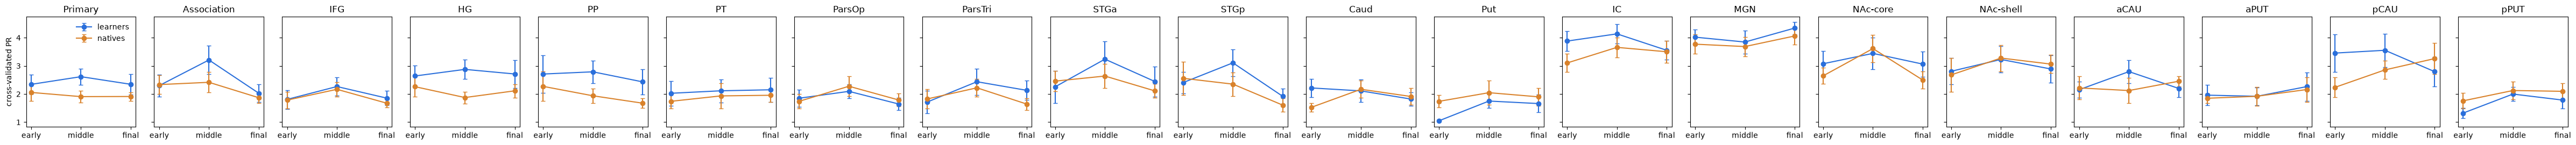

In [4]:
bilat = gs.bilateral_mean(pr)
regions = list(mvd.COMPOSITES) + [r for r in bilat.region.unique() if r not in mvd.COMPOSITES]
fig, axes = plt.subplots(1, len(regions), figsize=(2.4 * len(regions), 2.8), sharey=True)
for ax, region in zip(axes, regions):
    sub = bilat[bilat.region == region]
    for group in gs.GROUPS:
        g = sub[sub.participant_group == group].groupby('learning_stage').beta
        mean, sem = g.mean().reindex(gs.STAGE_ORDER), g.sem().reindex(gs.STAGE_ORDER)
        ax.errorbar(range(3), mean, yerr=sem, marker='o', capsize=3, color=colors[group], label=labels[group])
    ax.set_xticks(range(3), gs.STAGE_ORDER)
    ax.set_title(region)
axes[0].set_ylabel('cross-validated PR')
axes[0].legend(frameon=False)
fig.tight_layout()

## 3. Planned test: PR trend, learners vs. natives

Per-participant `[-1, 0, 1]` trend (final − early), Primary composite (HG + PT + PP, hemispheres pooled), the same battery as the striatal planned test: within each group (t, exact sign-flip, LOSO, bootstrap) and between groups (Welch, group-label permutation, LOSO, bootstrap CI). A negative trend is a decline. Association (STGa, STGp) and IFG (pars opercularis, pars triangularis) composites alongside.

Each composite is the mean of the member regions' PR (`multivariate_data.COMPOSITES`). Primary matches FLT2's notebook; FLT2 grouped STG and IFG into one association composite, split here because IFG isn't auditory association cortex.

In [5]:
trends = gs.subject_trends(pr)
planned = pd.concat([gs.trend_group_difference(trends, 'PRcv', region, n_perms=n_perms, n_boot=n_boot, seed=seed)
                     for region in mvd.COMPOSITES], ignore_index=True)
planned.to_csv(os.path.join(out_dir, 'pr_trend_planned.tsv'), sep='\t', index=False)
planned.round(3)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.002,0.006,0.996,0.996,0/12,-0.865,0.781,PRcv,Primary
1,Mandarin trend vs 0,13,-0.144,-0.497,0.628,0.646,0/13,-0.715,0.377,PRcv,Primary
2,non-Mandarin - Mandarin (Welch),25,0.147,0.280,0.782,0.789,0/25,-0.875,1.105,PRcv,Primary
3,non-Mandarin trend vs 0,12,-0.268,-0.532,0.605,0.603,0/12,-1.190,0.707,PRcv,Association
4,Mandarin trend vs 0,13,-0.465,-1.380,0.193,0.201,0/13,-1.127,0.139,PRcv,Association
5,non-Mandarin - Mandarin (Welch),25,0.197,0.325,0.749,0.753,0/25,-0.924,1.382,PRcv,Association
6,non-Mandarin trend vs 0,12,0.045,0.102,0.921,0.919,0/12,-0.788,0.885,PRcv,IFG
7,Mandarin trend vs 0,13,-0.109,-0.301,0.768,0.775,0/13,-0.833,0.533,PRcv,IFG
8,non-Mandarin - Mandarin (Welch),25,0.155,0.269,0.791,0.795,0/25,-0.895,1.244,PRcv,IFG


## 4. Mixed model: group × stage × level

`PR ~ group * stage * level + (1 | participant)` on the three composites (Primary, Association, IFG; plan R5), replacing FLT2's per-stage two-way decompositions. Stage as a categorical factor (early = reference).

In [6]:
composite = bilat[bilat.region.isin(mvd.COMPOSITES)].rename(
    columns={'beta': 'PRcv', 'participant_group': 'group', 'learning_stage': 'stage', 'region': 'level'})
composite['stage'] = pd.Categorical(composite.stage, categories=gs.STAGE_ORDER)
mixed = smf.mixedlm('PRcv ~ C(group, Treatment("Mandarin")) * stage * level',
                    composite, groups=composite.participant_id).fit(reml=True)
mixed.summary()

/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/ix1/bchandrasekaran/krs228/software/

<class 'statsmodels.iolib.summary2.Summary'>
"""
                                           Mixed Linear Model Regression Results
===========================================================================================================================
Model:                                    MixedLM                       Dependent Variable:                       PRcv     
No. Observations:                         225                           Method:                                   REML     
No. Groups:                               25                            Scale:                                    1.0117   
Min. group size:                          9                             Log-Likelihood:                           -330.0912
Max. group size:                          9                             Converged:                                No       
Mean group size:                          9.0                                                                              
---------------------------------------------------------------------------------------------------------------------------
                                                                                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                                         2.334    0.308  7.586 0.000  1.731  2.937
C(group, Treatment("Mandarin"))[T.non-Mandarin]                                  -0.037    0.444 -0.083 0.934 -0.907  0.834
stage[T.middle]                                                                   0.081    0.395  0.205 0.837 -0.692  0.854
stage[T.final]                                                                   -0.465    0.395 -1.180 0.238 -1.239  0.308
level[T.IFG]                                                                     -0.551    0.395 -1.396 0.163 -1.324  0.222
level[T.Primary]                                                                 -0.279    0.395 -0.706 0.480 -1.052  0.495
C(group, Treatment("Mandarin"))[T.non-Mandarin]:stage[T.middle]                   0.830    0.569  1.458 0.145 -0.286  1.946
C(group, Treatment("Mandarin"))[T.non-Mandarin]:stage[T.final]                    0.197    0.569  0.346 0.729 -0.919  1.313
C(group, Treatment("Mandarin"))[T.non-Mandarin]:level[T.IFG]                      0.062    0.569  0.109 0.913 -1.054  1.178
C(group, Treatment("Mandarin"))[T.non-Mandarin]:level[T.Primary]                  0.324    0.569  0.569 0.570 -0.792  1.440
stage[T.middle]:level[T.IFG]                                                      0.302    0.558  0.541 0.589 -0.792  1.395
stage[T.final]:level[T.IFG]                                                       0.356    0.558  0.638 0.523 -0.738  1.450
stage[T.middle]:level[T.Primary]                                                 -0.230    0.558 -0.412 0.681 -1.323  0.864
stage[T.final]:level[T.Primary]                                                   0.321    0.558  0.575 0.565 -0.773  1.415
C(group, Treatment("Mandarin"))[T.non-Mandarin]:stage[T.middle]:level[T.IFG]     -0.756    0.805 -0.939 0.348 -2.335  0.822
C(group, Treatment("Mandarin"))[T.non-Mandarin]:stage[T.final]:level[T.IFG]      -0.042    0.805 -0.052 0.958 -1.621  1.536
C(group, Treatment("Mandarin"))[T.non-Mandarin]:stage[T.middle]:level[T.Primary] -0.408    0.805 -0.507 0.612 -1.987  1.170
C(group, Treatment("Mandarin"))[T.non-Mandarin]:stage[T.final]:level[T.Primary]  -0.050    0.805 -0.062 0.950 -1.629  1.528
Group Var                                                                         0.219    0.141                           
===========================================================================================================================

"""

## 5. Exploratory: per-region tests

FDR across regions within each family. Stage-averaged group differences, trend group differences and the group × stage ANOVA.

In [7]:
per_region = pr[~pr.region.isin(mvd.COMPOSITES)]
level_diff = gs.group_difference_tests(per_region, contrasts=('PRcv',), n_perms=n_perms, seed=seed)
trend_diff = gs.trend_difference_tests(gs.subject_trends(per_region), contrasts=('PRcv',), n_perms=n_perms, seed=seed)
anova = gs.group_by_stage_anova(per_region)
for name, table in [('pr_group-difference', level_diff), ('pr_trend-difference', trend_diff),
                    ('pr_group-by-stage-anova', anova)]:
    table.to_csv(os.path.join(out_dir, f'{name}.tsv'), sep='\t', index=False)
level_diff.round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory,PRcv,HG,12,13,2.726,2.082,0.644,2.422,0.025,0.983,0.152,1.813,0.022,0.166
1,auditory,PRcv,PP,12,13,2.653,1.937,0.716,2.097,0.047,0.839,0.021,1.658,0.048,0.166
2,auditory,PRcv,PT,12,13,2.066,1.876,0.190,0.548,0.589,0.222,-0.565,1.009,0.590,0.688
3,auditory,PRcv,ParsOp,12,13,1.863,1.934,-0.072,-0.304,0.764,-0.120,-0.905,0.665,0.769,0.764
4,auditory,PRcv,ParsTri,12,13,2.093,1.864,0.229,0.707,0.487,0.286,-0.503,1.074,0.484,0.682
5,auditory,PRcv,STGa,12,13,2.693,2.360,0.333,0.861,0.400,0.349,-0.441,1.140,0.398,0.682
6,auditory,PRcv,STGp,12,13,2.431,2.155,0.275,0.777,0.446,0.306,-0.483,1.096,0.449,0.682
7,striatum-whole,PRcv,Caud,12,13,2.049,1.838,0.211,0.830,0.416,0.334,-0.456,1.125,0.407,0.416
8,striatum-whole,PRcv,Put,12,13,1.457,1.864,-0.407,-1.742,0.096,-0.687,-1.494,0.121,0.102,0.192
9,subcort-aud,PRcv,IC,12,13,3.856,3.420,0.436,1.298,0.207,0.517,-0.281,1.315,0.205,0.414


In [8]:
trend_diff.round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory,PRcv,HG,11,13,-0.052,-0.146,0.094,0.117,0.908,0.050,-0.753,0.853,0.904,0.908
1,auditory,PRcv,PP,11,12,-0.149,-0.642,0.493,0.500,0.624,0.213,-0.607,1.034,0.621,0.908
2,auditory,PRcv,PT,11,13,0.135,0.214,-0.079,-0.128,0.899,-0.053,-0.856,0.750,0.897,0.908
3,auditory,PRcv,ParsOp,12,13,-0.206,0.046,-0.252,-0.446,0.660,-0.179,-0.965,0.608,0.663,0.908
4,auditory,PRcv,ParsTri,12,12,0.417,-0.196,0.613,0.854,0.402,0.349,-0.457,1.155,0.407,0.908
5,auditory,PRcv,STGa,9,12,0.486,-0.374,0.861,1.003,0.339,0.491,-0.386,1.368,0.294,0.908
6,auditory,PRcv,STGp,10,12,-0.508,-1.083,0.575,0.674,0.508,0.279,-0.564,1.123,0.551,0.908
7,striatum-whole,PRcv,Caud,12,12,-0.394,0.421,-0.815,-1.640,0.116,-0.669,-1.492,0.153,0.115,0.232
8,striatum-whole,PRcv,Put,8,11,0.490,0.322,0.168,0.332,0.744,0.147,-0.765,1.059,0.759,0.744
9,subcort-aud,PRcv,IC,12,13,-0.327,0.398,-0.725,-1.067,0.297,-0.427,-1.221,0.366,0.297,0.594


In [9]:
anova[anova.q < .05].round(3)

,network,contrast,region,effect,F,df1,df2,p,np2,n_per_group,q


## 6. Checks: signal strength, split type, plain PR

**a. Signal strength.** PRcv reads low when the cross-validated signal is weak. If `cvsignal` changes across stages or differs between groups in the same direction that would produce the PRcv result, the PRcv result may be signal strength, not geometry. The same planned test on `cvsignal`, and the per-participant correlation of the two trends.

In [10]:
signal_trends = gs.subject_trends(cvsignal)
signal_planned = pd.concat([gs.trend_group_difference(signal_trends, 'cvsignal', region, n_perms=n_perms,
                                                      n_boot=n_boot, seed=seed)
                            for region in mvd.COMPOSITES], ignore_index=True)
both = trends.merge(signal_trends, on=['participant_id', 'participant_group', 'region'], suffixes=('_pr', '_signal'))
print(both[both.region.isin(mvd.COMPOSITES)].groupby(['region', 'participant_group'])
      .apply(lambda g: g.trend_pr.corr(g.trend_signal)).rename('r(PRcv trend, cvsignal trend)').round(2))
signal_planned.round(3)

region       participant_group
Association  Mandarin             0.36
             non-Mandarin         0.74
IFG          Mandarin             0.76
             non-Mandarin         0.47
Primary      Mandarin             0.26
             non-Mandarin         0.68
Name: r(PRcv trend, cvsignal trend), dtype: float64


,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,-0.012,-0.770,0.458,0.466,0/12,-0.040,0.017,cvsignal,Primary
1,Mandarin trend vs 0,13,-0.005,-0.294,0.774,0.765,0/13,-0.039,0.030,cvsignal,Primary
2,non-Mandarin - Mandarin (Welch),25,-0.006,-0.267,0.792,0.796,0/25,-0.051,0.038,cvsignal,Primary
3,non-Mandarin trend vs 0,12,0.005,0.323,0.752,0.751,0/12,-0.020,0.033,cvsignal,Association
4,Mandarin trend vs 0,13,-0.023,-1.377,0.194,0.195,1/13,-0.054,0.008,cvsignal,Association
5,non-Mandarin - Mandarin (Welch),25,0.028,1.257,0.221,0.230,0/25,-0.013,0.070,cvsignal,Association
6,non-Mandarin trend vs 0,12,0.006,0.300,0.769,0.768,0/12,-0.034,0.044,cvsignal,IFG
7,Mandarin trend vs 0,13,-0.034,-1.778,0.101,0.103,2/13,-0.070,0.002,cvsignal,IFG
8,non-Mandarin - Mandarin (Welch),25,0.041,1.435,0.165,0.167,0/25,-0.013,0.094,cvsignal,IFG


**b. Split type, natives.** Natives' responses shouldn't change with learning, so for them the repetition split (`PRcv`) and the run split (`PRcvrun`) should agree. A systematic difference there points to noise shared within runs (which the repetition split can't remove), not learning. In learners a difference is expected early.

In [11]:
pr_run = mvd.load_dimensionality(dim_dir, participants, 'PRcvrun')
split = gs.bilateral_mean(mvd.load_dimensionality(dim_dir, participants, 'PRcv')).merge(
    gs.bilateral_mean(pr_run), on=['network', 'participant_id', 'participant_group', 'region', 'learning_stage'],
    suffixes=('_rep', '_run'))
split['rep_minus_run'] = split.beta_rep - split.beta_run
split.groupby(['participant_group', 'learning_stage']).agg(
    rep_minus_run=('rep_minus_run', 'mean'), r=('beta_rep', lambda x: x.corr(split.loc[x.index, 'beta_run']))).round(3)

rep_minus_run      r
participant_group learning_stage                      
Mandarin          early                  -0.073  0.407
                  final                   0.117  0.483
                  middle                  0.244  0.356
non-Mandarin      early                   0.334  0.417
                  final                   0.105  0.452
                  middle                  0.560  0.442

**c. Plain PR and voxel count.** Plain PR for comparison with FLT2's earlier results (noise-inflated; don't report), and whether PRcv tracks ROI size across participants.

In [12]:
plain = mvd.add_composites(mvd.load_dimensionality(dim_dir, participants, 'PR'))
plain_planned = pd.concat([gs.trend_group_difference(gs.subject_trends(plain), 'PR', region, n_perms=n_perms,
                                                     n_boot=n_boot, seed=seed)
                           for region in mvd.COMPOSITES], ignore_index=True)
size = gs.bilateral_mean(pr).groupby(['participant_id', 'region'], as_index=False).beta.mean().merge(
    nvoxels.assign(region=nvoxels.region_hemi.map(lambda rh: mvd.split_region_hemi(rh)[0])).groupby(['participant_id', 'region'], as_index=False).n_voxels.sum())
print(size.groupby('region').apply(lambda g: g.beta.corr(g.n_voxels)).rename('r(PRcv, n voxels)').round(2))
plain_planned.round(3)

region
Caud         0.24
HG           0.02
IC           0.56
MGN          0.37
NAc-core     0.39
NAc-shell   -0.05
PP          -0.08
PT          -0.14
ParsOp      -0.06
ParsTri      0.03
Put          0.05
STGa         0.17
STGp         0.07
aCAU         0.25
aPUT        -0.16
pCAU         0.16
pPUT         0.15
Name: r(PRcv, n voxels), dtype: float64


,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,-0.255,-1.884,0.086,0.089,1/12,-0.514,-0.007,PR,Primary
1,Mandarin trend vs 0,13,-0.408,-1.756,0.105,0.101,1/13,-0.853,-0.000,PR,Primary
2,non-Mandarin - Mandarin (Welch),25,0.153,0.569,0.576,0.588,0/25,-0.338,0.665,PR,Primary
3,non-Mandarin trend vs 0,12,-0.375,-2.121,0.057,0.057,3/12,-0.710,-0.050,PR,Association
4,Mandarin trend vs 0,13,-0.467,-1.868,0.086,0.089,1/13,-0.950,-0.009,PR,Association
5,non-Mandarin - Mandarin (Welch),25,0.092,0.301,0.766,0.773,0/25,-0.469,0.665,PR,Association
6,non-Mandarin trend vs 0,12,-0.728,-3.134,0.010,0.012,12/12,-1.156,-0.279,PR,IFG
7,Mandarin trend vs 0,13,0.019,0.096,0.925,0.927,0/13,-0.371,0.378,PR,IFG
8,non-Mandarin - Mandarin (Welch),25,-0.747,-2.437,0.023,0.025,25/25,-1.304,-0.172,PR,IFG


## 7. Export for analysis B

Per-participant PRcv trends (every region and composite) for `integration_B` (plan R7).

In [13]:
trends.to_csv(os.path.join(out_dir, 'pr_trend_scalars.tsv'), sep='\t', index=False)
print('wrote', os.path.join(out_dir, 'pr_trend_scalars.tsv'))

wrote /ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/glmsingle_fmriprep-25.2.5_space-T1w/stats_two-group/pr_trend_scalars.tsv
